In [94]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [95]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import (
    train_test_split,
    cross_val_score
)

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [96]:
# Load the California Housing dataset
housing = fetch_california_housing(as_frame=True)

# Create a DataFrame
df = housing.frame.copy()

print("Dataset loaded successfully!")
print("\nFirst 5 records:")
display(df.head())

print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset loaded successfully!

First 5 records:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422



Dataset Shape: (20640, 9)

Column Names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [97]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# Remove duplicate records, if any
df = df.drop_duplicates().copy()

# Remove rows containing missing values, if any
df = df.dropna().copy()

print("\nDataset Shape After Cleaning:", df.shape)

Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Duplicate Rows: 0

Dataset Shape After Cleaning: (20640, 9)


Statistical Summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


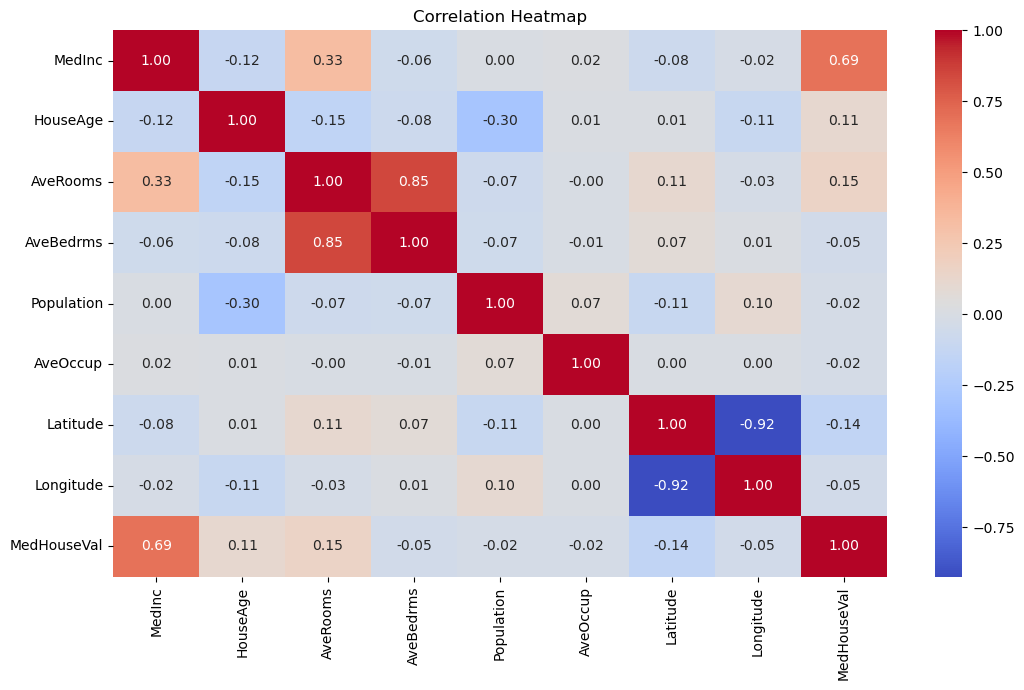

In [98]:
# Statistical summary
print("Statistical Summary:")
display(df.describe().round(2))

# Correlation Heatmap
plt.figure(figsize=(11, 7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

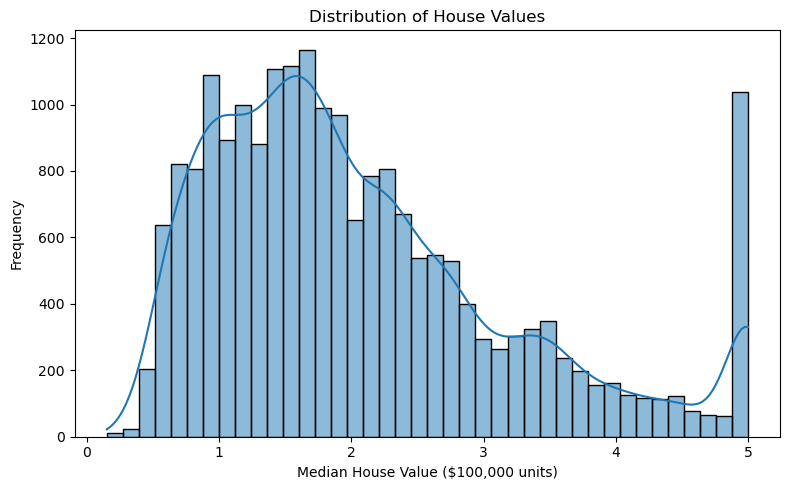

In [99]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["MedHouseVal"],
    bins=40,
    kde=True
)

plt.title("Distribution of House Values")
plt.xlabel("Median House Value ($100,000 units)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [100]:
# Input features
X = df.drop(columns=["MedHouseVal"])

# Target variable
y = df["MedHouseVal"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (20640, 8)
Target Shape: (20640,)


In [101]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 16512
Testing Records: 4128


In [102]:
# Linear Regression
linear_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

# Random Forest Regression
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train both models
linear_model.fit(X_train, y_train)

random_forest_model.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [103]:
models = {
    "Linear Regression": linear_model,
    "Random Forest": random_forest_model
}

results = []
predictions = {}

for name, model in models.items():

    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

print("Model Performance Comparison:")
display(results_df.round(4))

Model Performance Comparison:


,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.5332,0.7456,0.5758
1,Random Forest,0.3275,0.5053,0.8051


In [104]:
cv_scores = cross_val_score(
    linear_model,
    X_train,
    y_train,
    cv=5,
    scoring="r2"
)

print("Cross-validation R2 Scores:")
print(np.round(cv_scores, 4))

print("\nMean Cross-validation R2:")
print(round(cv_scores.mean(), 4))

Cross-validation R2 Scores:
[0.6201 0.613  0.6134 0.6107 0.6002]

Mean Cross-validation R2:
0.6115


Model selected based on test RMSE: Random Forest


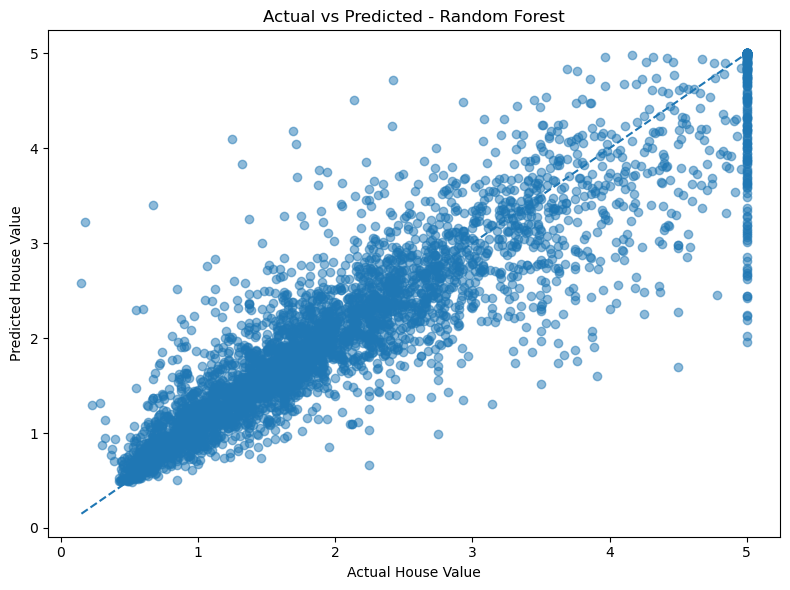

In [105]:
best_model_name = results_df.sort_values(
    by="RMSE"
).iloc[0]["Model"]

best_model = models[best_model_name]

y_pred = predictions[best_model_name]

print("Model selected based on test RMSE:", best_model_name)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title(f"Actual vs Predicted - {best_model_name}")
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")

plt.tight_layout()
plt.show()

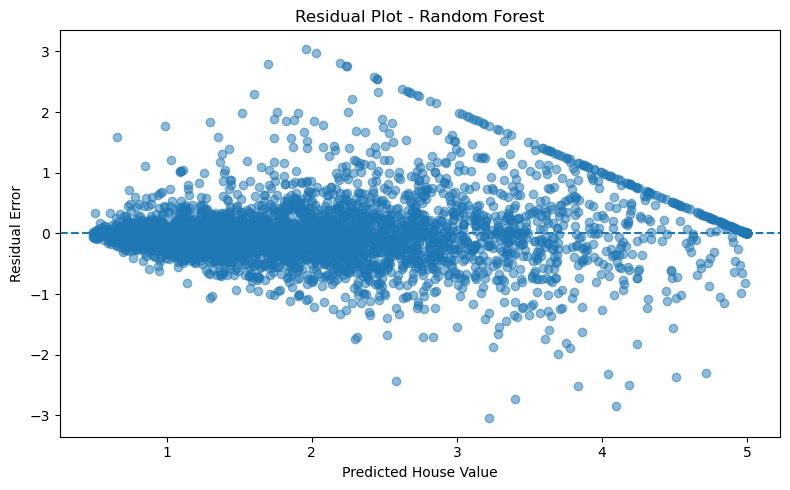

In [106]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title(f"Residual Plot - {best_model_name}")
plt.xlabel("Predicted House Value")
plt.ylabel("Residual Error")

plt.tight_layout()
plt.show()

In [107]:
# Use one existing record as an example
new_house = X_test.iloc[[0]].copy()

predicted_value = best_model.predict(new_house)[0]

print("Example House Features:")
display(new_house)

print(
    f"Predicted Median House Value: "
    f"${predicted_value * 100000:,.2f}"
)

Example House Features:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
20046,1.6812,25.0,4.192201,1.022284,1392.0,3.877437,36.06,-119.01


Predicted Median House Value: $50,950.00


In [108]:
print("=" * 45)
print("HOUSE PRICE PREDICTION PROJECT SUMMARY")
print("=" * 45)

print("Dataset: California Housing Dataset")
print("Total Records:", len(df))
print("Number of Features:", X.shape[1])
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nModel Comparison:")
display(results_df.round(4))

print("\nSelected Model:", best_model_name)

print("\nProject Completed Successfully!")

HOUSE PRICE PREDICTION PROJECT SUMMARY
Dataset: California Housing Dataset
Total Records: 20640
Number of Features: 8
Training Records: 16512
Testing Records: 4128

Model Comparison:


,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.5332,0.7456,0.5758
1,Random Forest,0.3275,0.5053,0.8051



Selected Model: Random Forest

Project Completed Successfully!
